# 05 - IA : détection d'anomalies par autoencodeur profond

> **REAL MARKET DATA — LOCAL CSV IMPORTS, NOT SYNTHETIC DATA.**

Ce prototype apprend uniquement sur les périodes normales. Les 10 corrélations dynamiques uniques entre les cinq banques sont reconstruites avec un autoencodeur PyTorch; les erreurs élevées signalent des changements de régime.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# nbconvert may launch the kernel with notebooks/ as its working directory.
project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.real_data import load_real_dataset
from src.garch import fit_garch_panel, align_standardized_residuals
from src.dcc_garch import fit_dcc
from src.ml import CorrelationAutoencoder, train_autoencoder, upper_triangle_features

_, returns, _, combined = load_real_dataset()
garch_results = fit_garch_panel(returns)
standardized_residuals = align_standardized_residuals(garch_results)
dcc = fit_dcc(standardized_residuals)

features = upper_triangle_features(dcc.correlations)
stress = combined.loc[dcc.observation_dates, "stress_period"].astype(bool)

assert features.shape[1] == 10
print("DCC shape:", dcc.correlations.shape)
print("Feature shape:", features.shape)
print("Stress observations:", int(stress.sum()))

DCC shape: (736, 5, 5)
Feature shape: (736, 10)
Stress observations: 0


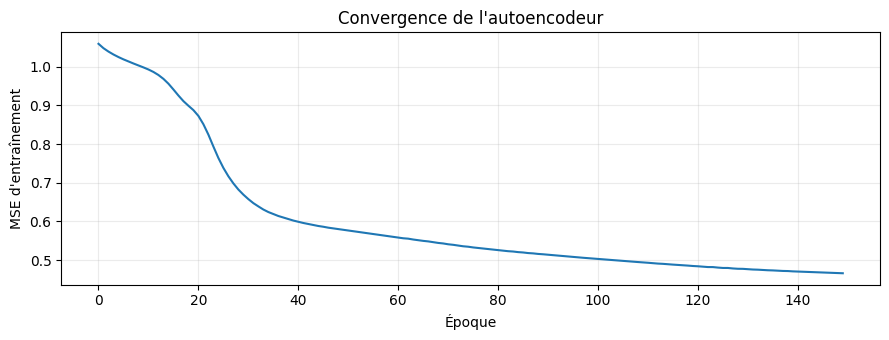

In [8]:
# Séparation chronologique : les 70 premiers % servent à l'entraînement.
split_index = int(0.70 * len(features))
train_mask = np.arange(len(features)) < split_index
train_mask &= ~stress.to_numpy(dtype=bool)

# Standardisation estimée uniquement sur les observations normales d'entraînement.
feature_mean = features[train_mask].mean(axis=0)
feature_std = features[train_mask].std(axis=0, ddof=0)
feature_std = np.where(feature_std > 1e-8, feature_std, 1.0)
train_features = (features[train_mask] - feature_mean) / feature_std
all_features = (features - feature_mean) / feature_std

model = CorrelationAutoencoder(input_dim=10, latent_dim=3, hidden_dims=(8, 5))
training = train_autoencoder(
    train_features,
    model=model,
    epochs=150,
    batch_size=32,
    learning_rate=1e-3,
    seed=20251115,
    device="cpu",
)

plt.figure(figsize=(9, 3.5))
plt.plot(training.losses)
plt.xlabel("Époque")
plt.ylabel("MSE d'entraînement")
plt.title("Convergence de l'autoencodeur")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [3]:
train_errors = model.score(train_features)
threshold = float(np.percentile(train_errors, 99.0))
anomaly_scores = model.score(all_features)
alert = anomaly_scores > threshold

anomaly_frame = pd.DataFrame(
    {
        "anomaly_score": anomaly_scores,
        "threshold": threshold,
        "alert": alert,
        "known_stress": stress.to_numpy(dtype=bool),
    },
    index=dcc.observation_dates,
)

print("Seuil au 99e percentile:", threshold)
print("Nombre d'alertes:", int(alert.sum()))
display(anomaly_frame.tail(20))

Seuil au 99e percentile: 5.901012420654297
Nombre d'alertes: 8


,anomaly_score,threshold,alert,known_stress
date,,,,
2026-10-14,0.006297,5.901012,False,False
2026-10-15,0.003308,5.901012,False,False
2026-10-16,0.032951,5.901012,False,False
2026-10-19,0.838436,5.901012,False,False
2026-10-20,0.136383,5.901012,False,False
2026-10-21,0.013670,5.901012,False,False
2026-10-22,0.015765,5.901012,False,False
2026-10-23,0.667175,5.901012,False,False
2026-10-26,0.251048,5.901012,False,False


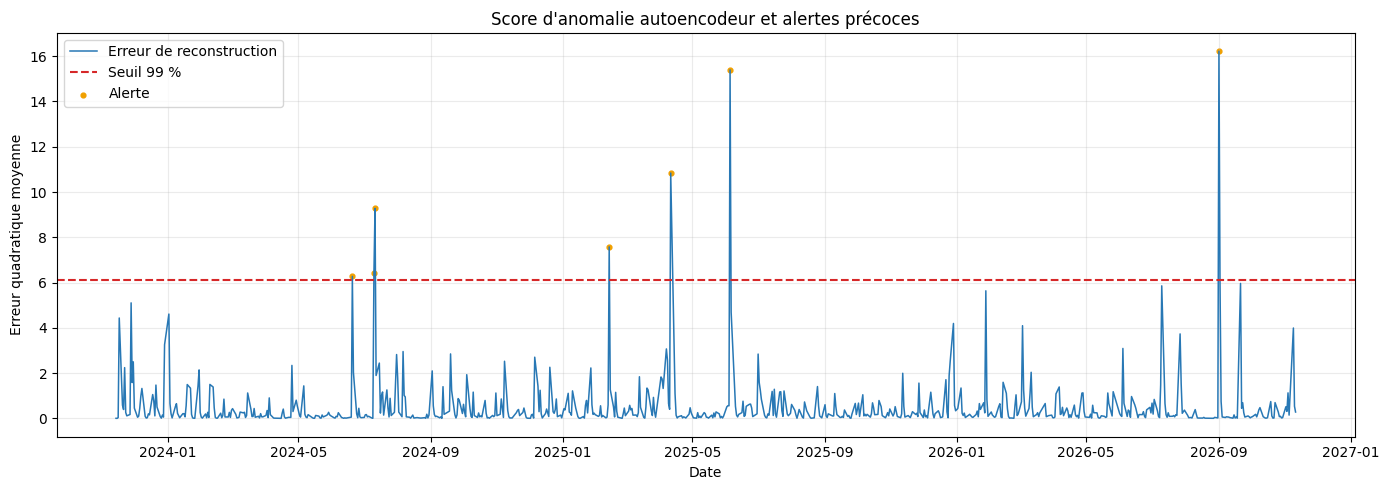

In [9]:
# Recompute scores if this plotting cell is run independently after a kernel restart.
if "anomaly_frame" not in globals():
    train_errors = model.score(train_features)
    threshold = float(np.percentile(train_errors, 99.0))
    anomaly_scores = model.score(all_features)
    alert = anomaly_scores > threshold
    anomaly_frame = pd.DataFrame(
        {
            "anomaly_score": anomaly_scores,
            "threshold": threshold,
            "alert": alert,
            "known_stress": stress.to_numpy(dtype=bool),
        },
        index=dcc.observation_dates,
    )

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(anomaly_frame.index, anomaly_frame["anomaly_score"], color="#2878B5", lw=1.1, label="Erreur de reconstruction")
ax.axhline(threshold, color="#D62728", ls="--", lw=1.5, label="Seuil 99 %")
ax.scatter(
    anomaly_frame.index[alert],
    anomaly_frame.loc[alert, "anomaly_score"],
    color="#F0A000", s=12, label="Alerte",
)
if anomaly_frame["known_stress"].any():
    stress_dates = anomaly_frame.index[anomaly_frame["known_stress"]]
    ax.axvspan(
        stress_dates.min(), stress_dates.max(),
        color="#D62728", alpha=0.08, label="Périodes de stress connues",
    )
ax.set_title("Score d'anomalie autoencodeur et alertes précoces")
ax.set_xlabel("Date")
ax.set_ylabel("Erreur quadratique moyenne")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

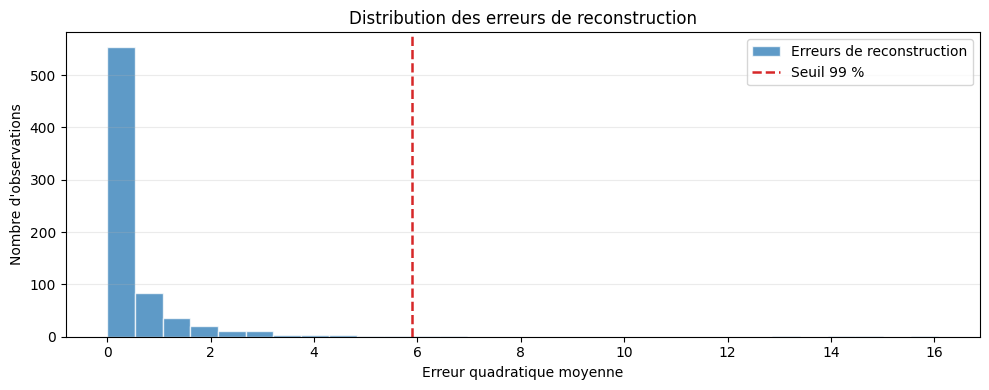

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(
    anomaly_scores,
    bins=30,
    color="#2878B5",
    alpha=0.75,
    edgecolor="white",
    label="Erreurs de reconstruction",
)
ax.axvline(
    threshold,
    color="#D62728",
    linestyle="--",
    linewidth=1.8,
    label="Seuil 99 %",
)
ax.set_title("Distribution des erreurs de reconstruction")
ax.set_xlabel("Erreur quadratique moyenne")
ax.set_ylabel("Nombre d'observations")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()